# **Project Name**    -  Facial Emotion Recognition


##### **Project Type**    - Convolutional Neural Network (Deep Learning) - Classification
##### **Contribution**    - Individual


# **Project Summary -**

DeepFER refers to a deep learning system project based on the application of Convolutional Neural Network models with transfer learning technique to perform facial expression recognition and classification into seven different emotions including anger, sadness, happiness, fear, neutrality, disgust, and surprise. The project requires image preprocessing and augmentation, model training and performance evaluation through parameters like accuracy, precision, recall, and F1-score. The resulting model is intended to facilitate real-time emotion recognition from images or video feeds through an easy-to-use application interface.


# **GitHub Link -**

https://github.com/Someshwar24/DeepFER-Facial-Emotion-Recognition-Using-Deep-Learning

# **Problem Statement**


The problem of recognizing emotions from faces is a difficult one owing to inconsistencies arising due to different facial expressions, lighting conditions, quality of image, and personal differences. Conventional methods may find it difficult to accurately detect minute emotional expressions. The objective of DeepFER is to create an emotion recognition system based on deep learning through the use of Convolutional Neural Networks (CNNs) and transfer learning. This system classifies facial images into seven emotion classes including angry, sad, happy, fear, neutral, disgust, and surprise.

# ***Let's Begin !***

In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense,Dropout,Input
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("someshwar2410/facial-expression-recognition")

print(dataset_path)

Using Colab cache for faster access to the 'facial-expression-recognition' dataset.
/kaggle/input/facial-expression-recognition


In [ ]:
import os

images_path = os.path.join(dataset_path, "images")

print(os.listdir(images_path))

['validation', 'train']


In [ ]:
train_path = os.path.join(images_path,"train")

print(os.listdir(train_path))

val_path = os.path.join(images_path,"validation")

print(os.listdir(val_path))

['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']
['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']


In [ ]:
# Load the training and Validation dataset

img_size = (224,224)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(train_path,image_size=img_size,batch_size=batch_size,shuffle=True,seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(val_path,image_size=img_size,batch_size=batch_size,shuffle=False)

Found 28821 files belonging to 7 classes.
Found 7066 files belonging to 7 classes.


In [ ]:
class_names = train_ds.class_names

print("Emotion classes:", class_names)
print("Number of classes:", len(class_names))

Emotion classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7


In [ ]:
# Count the images in each emotion folder
for emotion in class_names:

    emotion_path = os.path.join(train_path, emotion)

    image_count = len(os.listdir(emotion_path))

    print(f"{emotion}: {image_count}")

angry: 3993
disgust: 436
fear: 4103
happy: 7164
neutral: 4982
sad: 4938
surprise: 3205


In [ ]:
# Normalize the training images
train_ds = train_ds.map(
    lambda images, labels: (images / 255.0, labels)
)

# Normalize the validation images
val_ds = val_ds.map(
    lambda images, labels: (images / 255.0, labels)
)

In [ ]:
from tensorflow.keras.layers import (Conv2D,MaxPooling2D,Flatten,Dense,Dropout)

model = Sequential([Conv2D(32,(3,3),activation="relu",input_shape=(224,224,3)),
                  MaxPooling2D(2,2),
                    Conv2D(64,(3,3),activation="relu"),
                    MaxPooling2D(2,2),
                    Flatten(),
                    Dense(128,activation="relu"),
                    Dropout(0.5),
                    Dense(7,activation="softmax")])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,908,295 (91.20 MB)

 Trainable params: 23,908,295 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [ ]:
history = model.fit(train_ds,validation_data=val_ds,epochs=10)

Epoch 1/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 129s 134ms/step - accuracy: 0.2850 - loss: 1.8127 - val_accuracy: 0.3556 - val_loss: 1.6698
Epoch 2/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.3573 - loss: 1.6348 - val_accuracy: 0.3521 - val_loss: 1.6384
Epoch 3/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.3863 - loss: 1.5653 - val_accuracy: 0.3998 - val_loss: 1.5539
Epoch 4/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 46s 51ms/step - accuracy: 0.4280 - loss: 1.4777 - val_accuracy: 0.4186 - val_loss: 1.5190
Epoch 5/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 50s 56ms/step - accuracy: 0.4694 - loss: 1.3715 - val_accuracy: 0.4192 - val_loss: 1.5246
Epoch 6/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.5153 - loss: 1.2697 - val_accuracy: 0.4267 - val_loss: 1.5358
Epoch 7/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.5538 - loss: 1.1612 - val_accuracy: 0.4263 - val_loss: 1.5622
Epoch 8/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 46s 51ms/step - accuracy: 0.5953 - loss: 1.0574 

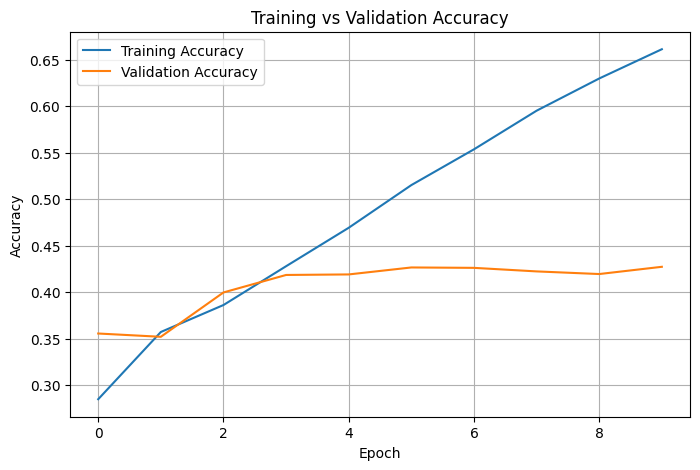

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

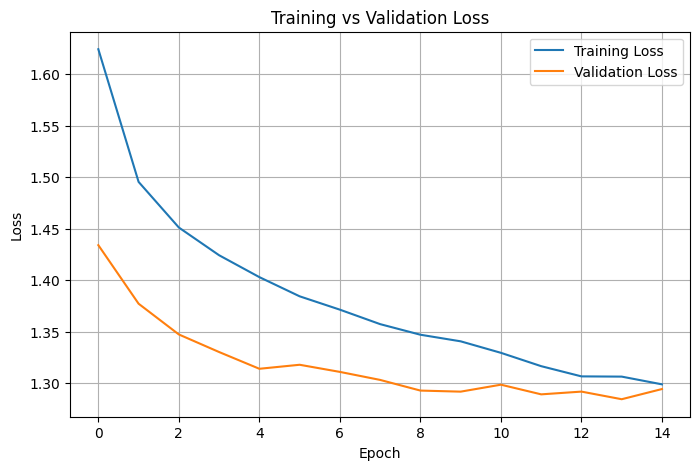

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,verbose=1,restore_best_weights=True)
check_point = tf.keras.callbacks.ModelCheckpoint(filepath="best_model.keras",monitor="val_loss",mode=min,save_best_only=True)

/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/model_checkpoint.py:138: UserWarning: ModelCheckpoint mode '<built-in function min>' is unknown, fallback to auto mode.
  super().__init__(monitor, mode, initial_value_threshold)


In [ ]:
# Try 2 with Earlystopping

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping, check_point],
    verbose=1
)

Epoch 1/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 54s 60ms/step - accuracy: 0.6902 - loss: 0.8057 - val_accuracy: 0.4254 - val_loss: 1.9893
Epoch 2/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.7139 - loss: 0.7546 - val_accuracy: 0.4227 - val_loss: 2.1217
Epoch 3/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.7313 - loss: 0.6989 - val_accuracy: 0.4274 - val_loss: 2.1804
Epoch 4/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 47s 52ms/step - accuracy: 0.7474 - loss: 0.6572 - val_accuracy: 0.4271 - val_loss: 2.2148
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


In [ ]:
# Try 3 with Transfer learning

import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

# Convert normalized images from [0, 1] to the range expected by MobileNetV2

mobilenet_preprocessing = tf.keras.Sequential([
    layers.Rescaling(255.0),
    layers.Lambda(preprocess_input)
])

In [ ]:
# Load MobileNetV2 with pretrained ImageNet weights

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Build the transfer-learning model

model = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # MobileNetV2 preprocessing
    mobilenet_preprocessing,

    # Pretrained feature extractor
    base_model,

    # Classification head
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    # Seven emotion classes
    layers.Dense(7, activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_deepfer_mobilenetv2.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

In [23]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 60s 54ms/step - accuracy: 0.3649 - loss: 1.6242 - val_accuracy: 0.4598 - val_loss: 1.4339
Epoch 2/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 36s 39ms/step - accuracy: 0.4228 - loss: 1.4954 - val_accuracy: 0.4745 - val_loss: 1.3771
Epoch 3/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 34s 38ms/step - accuracy: 0.4411 - loss: 1.4510 - val_accuracy: 0.4984 - val_loss: 1.3472
Epoch 4/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 35s 39ms/step - accuracy: 0.4493 - loss: 1.4241 - val_accuracy: 0.4960 - val_loss: 1.3302
Epoch 5/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 35s 39ms/step - accuracy: 0.4608 - loss: 1.4029 - val_accuracy: 0.5078 - val_loss: 1.3139
Epoch 6/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 35s 38ms/step - accuracy: 0.4643 - loss: 1.3843 - val_accuracy: 0.5068 - val_loss: 1.3178
Epoch 7/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 35s 39ms/step - accuracy: 0.4673 - loss: 1.3713 - val_accuracy: 0.5065 - val_loss: 1.3109
Epoch 8/15
901/901 ━━━━━━━━━━━━━━━━━━━━ 36s 40ms/step - accuracy: 0.4742 - loss: 1.3572 - 

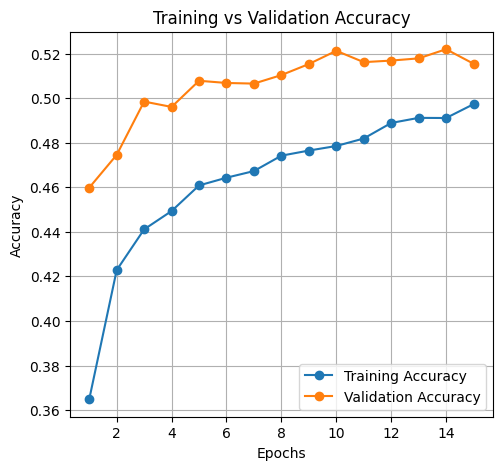

In [24]:
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
epochs = range(1, len(train_accuracy) + 1)

# Plot accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracy, marker='o', label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)


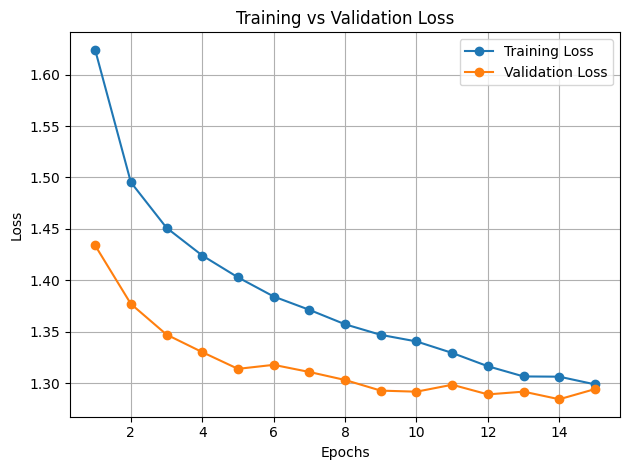

In [25]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(epochs, train_loss, marker='o', label='Training Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [26]:
val_loss,val_accuracy = model.evaluate(val_ds,verbose=1)

print(f"Validation Loss: {val_loss:.2f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

221/221 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.5219 - loss: 1.2843
Validation Loss: 1.28
Validation Accuracy: 52.19%


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Emotion class names in the same order as train_ds
class_names = [
    'angry', 'disgust', 'fear', 'happy',
    'neutral', 'sad', 'surprise'
]

def predict_emotion(image_path):

  image = load_img(image_path, target_size=(224, 224))

  image_array = img_to_array(image)

  image_array = image_array / 255.0

  image_array = np.expand_dims(image_array, axis=0)

  predictions = model.predict(image_array, verbose=0)

  predicted_index = np.argmax(predictions[0])
  predicted_emotion = class_names[predicted_index]
  confidence = predictions[0][predicted_index] * 100

  # Display image and prediction
  plt.imshow(image)
  plt.axis('off')
  plt.title(
      f"Predicted Emotion: {predicted_emotion}\n"
      f"Confidence: {confidence:.2f}%"
  )
  plt.show()

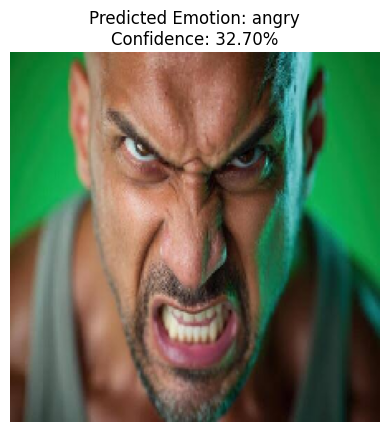

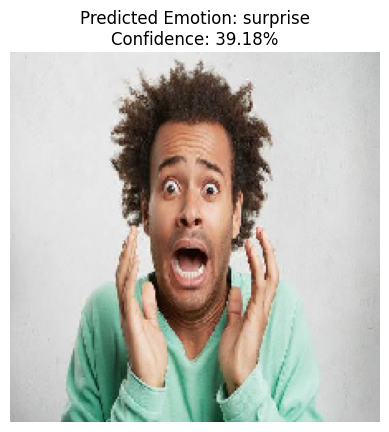

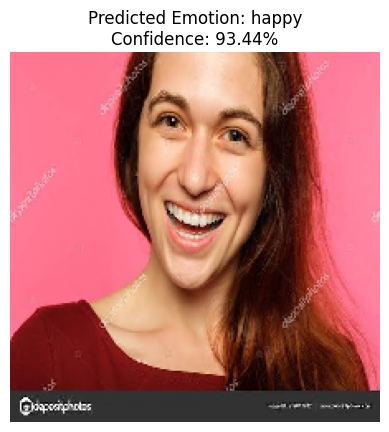

In [28]:
image_path = ["/content/Face1.jpg","/content/Face2.jpg","/content/Face3.jpg"]

for path in image_path:
  predict_emotion(path)

# **Conclusion**

The DeepFER project created a facial emotion detection system based on the Convolutional Neural Networks and using transfer learning based on the MobileNetV2. The model was trained to categorize faces according to seven different emotions: anger, disgust, fear, happiness, neutrality, sadness, and surprise.

The basic CNN architecture designed from scratch showed poor results compared to MobileNetV2. However, implementation of transfer learning with the help of MobileNetV2 provided a better learning performance of the model, which was about 52% in validation in the current experiment.

The project presents a good example of usage of transfer learning for the problem of facial expression classification.This project also proves the importance of evaluation of deep learning models with the help of validation metrics and visual predictions.
